# Histograms with segmentation

In [14]:
import cv2
import matplotlib.pyplot as plt

In [1]:
import pickle
from dataclasses import dataclass
from pathlib import Path

import numpy as np


@dataclass(frozen=True)
class ImageDataset:
    """Image paths paired with integer IDs in deterministic filename order."""

    paths: tuple[Path, ...]
    ids: np.ndarray

    def __len__(self) -> int:
        return len(self.paths)


def image_id(path: Path) -> int:
    """Parse IDs from both `00012.jpg` and `bbdd_00012.jpg`."""
    return int(path.stem.rsplit("_", 1)[-1])


def load_image_dataset(directory: str | Path) -> ImageDataset:
    directory = Path(directory)
    # Sorting is essential: submission row i must correspond to query image i.
    paths = tuple(sorted(directory.glob("*.jpg")))
    if not paths:
        raise FileNotFoundError(f"No JPG images found in {directory}")
    ids = np.asarray([image_id(path) for path in paths], dtype=int)
    if len(np.unique(ids)) != len(ids):
        raise ValueError(f"Duplicate image IDs found in {directory}")
    return ImageDataset(paths=paths, ids=ids)


def load_ground_truth(path: str | Path) -> list[list[int]]:
    with Path(path).open("rb") as stream:
        values = pickle.load(stream)
    return [[int(image_id) for image_id in relevant] for relevant in values]


In [5]:
# load the data

train_dataset = load_image_dataset("../data/BBDD")
ground_truth = load_ground_truth("../data/qsd1_w1/gt_corresps.pkl")

## Simple image segmentation and histogramization

In [15]:
def simple_segment_and_histogram(img , level,plot = False):
    # segment the image into level x level blocks and compute the histogram for each block
    h, w = img.shape[:2]
    block_h, block_w = h // level, w // level
    
    histograms = []
    for i in range(level):
        for j in range(level):
            block = img[i*block_h:(i+1)*block_h, j*block_w:(j+1)*block_w]
            hist = cv2.calcHist([block], [0, 1, 2], None, [8, 8, 8], [0, 256, 0, 256, 0, 256])
            histograms.append(hist.flatten())
            
    if plot:
        plt.figure(figsize=(10, 5))
        for idx, hist in enumerate(histograms):
            plt.subplot(level, level, idx + 1)
            plt.bar(range(len(hist)), hist)
            plt.title(f'Block {idx + 1}')
        plt.tight_layout()
        plt.show()
            
    return np.array(histograms)

ValueError: x and y can be no greater than 2D, but have shapes (756,) and (756, 1368, 3)

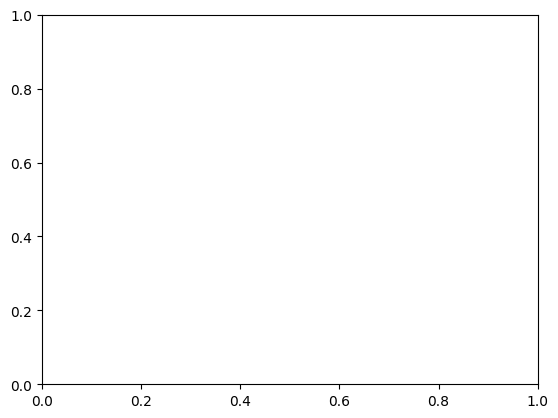

In [ ]:
image = cv2.imread(train_dataset.paths[0].as_posix())
plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()
